# 02 · Feature sets

**Question:** which molecular representation works best, and do physically motivated features help?

Feature sets compared (all with a log target):
- the precomputed sets from `precursor2cof-capacitance` (`cof_matched/rth_0.99/features/`), alone and in the
  combinations the old greedy selection picked
- **redox features (new):** counts of groups usually treated as redox-active in organic electrodes
  (C=O, imine C=N, aromatic N, nitrile, azo, nitro), the number of sites per heavy atom, and a
  **theoretical capacity** = 26801 · n_sites / MW (mAh/g, one electron per site). Capacity per gram
  should scale with active sites per mass, a ratio trees can't easily build from separate counts.
- **all RDKit 2D descriptors** (163 non-constant ones)
- our own count fingerprints: Morgan r=2 and atom pairs (2048 bits, no correlation filter)

Two models: random forest and CatBoost, fixed settings from notebook 01.

In [1]:
import os
import sys
import warnings

os.environ["PYTHONWARNINGS"] = "ignore"
warnings.filterwarnings("ignore")
sys.path.insert(0, os.path.abspath(".."))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from catboost import CatBoostRegressor
from scipy.stats import spearmanr
from sklearn.ensemble import RandomForestRegressor

from cofreg import plots
from cofreg.cv import repeated_folds, run_many
from cofreg.data import RESULTS_DIR, load_data, load_features, readable_names
from cofreg.features import count_fingerprint, rdkit_descriptors, redox_features
from cofreg.models import TargetTransformed

plots.style()
EXPERIMENT = "02_features"
data = load_data()
y = data.capacity_max.to_numpy()
smiles = data.smiles.tolist()
repeats = repeated_folds(y)

## Do the redox features relate to capacity?

Spearman correlation of each new feature with the target. Two groups never occur in the data (NaN).

,spearman
log_mw,-0.40
n_imine,-0.16
n_carbonyl,-0.13
n_redox_sites,-0.01
n_aromatic_n,0.02
n_nitro,0.09
heteroatom_capacity,0.22
n_nitrile,0.24
theoretical_capacity,0.30
redox_sites_per_heavy_atom,0.32


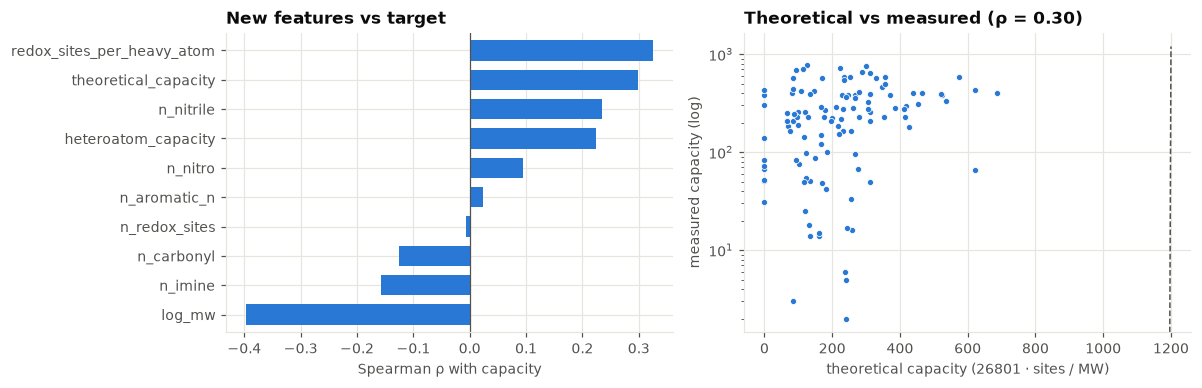

In [2]:
redox = redox_features(smiles)
corr = pd.Series({c: spearmanr(redox[c], y)[0] for c in redox.columns}).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
corr.dropna().plot.barh(ax=axes[0], color=plots.BLUE, width=0.7)
axes[0].axvline(0, color=plots.INK_2, linewidth=0.8)
axes[0].set(xlabel="Spearman ρ with capacity")
axes[0].set_title("New features vs target", loc="left")
axes[1].scatter(redox.theoretical_capacity, y, s=16, color=plots.BLUE, edgecolors="white", linewidths=0.5)
axes[1].plot([0, 1200], [0, 1200], color=plots.INK_2, linestyle="--", linewidth=1)
axes[1].set(yscale="log", xlabel="theoretical capacity (26801 · sites / MW)", ylabel="measured capacity (log)")
axes[1].set_title(f"Theoretical vs measured (ρ = {corr['theoretical_capacity']:.2f})", loc="left")
fig.tight_layout()
corr.round(2).to_frame("spearman")

The theoretical capacity correlates only weakly (ρ ≈ 0.3) and many substrates sit far above or below
the diagonal. A simple "count the active sites" view explains little, probably because the measured
value also depends on the COF and the cell, not only on the monomer.

In [3]:
rdkit = rdkit_descriptors(smiles)
morgan = count_fingerprint(smiles, "morgan", radius=2, size=2048)
atompair = count_fingerprint(smiles, "atompair", size=2048)
pre = {name: load_features(name) for name in ["descriptor", "custom_pattern", "ecfp", "estate", "functional_groups", "maccs"]}
cat = lambda *frames: pd.concat(frames, axis=1)

FEATURES = {
    **pre,
    "estate+fg (old RF best)": cat(pre["estate"], pre["functional_groups"]),
    "descriptor+ecfp+estate+fg (old BRR best)": cat(pre["descriptor"], pre["ecfp"], pre["estate"], pre["functional_groups"]),
    "all precomputed": cat(*pre.values()),
    "redox": redox,
    "redox+descriptor": cat(redox, pre["descriptor"]),
    "estate+fg+redox": cat(pre["estate"], pre["functional_groups"], redox),
    "rdkit": rdkit,
    "rdkit+redox": cat(rdkit, redox),
    "morgan2 (own)": morgan,
    "atompair (own)": atompair,
}
MODELS = {
    "rf": lambda: RandomForestRegressor(500, min_samples_leaf=2, max_features=0.3, random_state=0, n_jobs=1),
    "catboost": lambda: CatBoostRegressor(iterations=500, depth=4, learning_rate=0.03, verbose=0, thread_count=1, random_seed=0),
}
configs = [
    (f"{m}_log | {f}", TargetTransformed(make(), "log"), X, f)
    for m, make in MODELS.items()
    for f, X in FEATURES.items()
]
summary = run_many(configs, y, repeats, EXPERIMENT)
summary.to_csv(os.path.join(RESULTS_DIR, EXPERIMENT, "summary.csv"), index=False)

rf_log | descriptor                           MAPE 1.838±0.055  PA 0.639±0.008  RMSE 202.1±3.2  MALE 0.732  (3.1s)


rf_log | custom_pattern                       MAPE 2.947±0.077  PA 0.561±0.008  RMSE 214.9±2.5  MALE 0.919  (1.6s)


rf_log | ecfp                                 MAPE 1.880±0.051  PA 0.677±0.009  RMSE 189.6±2.1  MALE 0.726  (2.6s)


rf_log | estate                               MAPE 1.541±0.053  PA 0.670±0.005  RMSE 191.6±2.2  MALE 0.717  (1.8s)


rf_log | functional_groups                    MAPE 1.401±0.029  PA 0.665±0.008  RMSE 189.8±2.4  MALE 0.691  (1.8s)


...

catboost_log | estate+fg+redox                MAPE 1.528±0.144  PA 0.657±0.013  RMSE 193.6±5.6  MALE 0.715  (1.3s)


catboost_log | rdkit                          MAPE 1.669±0.111  PA 0.674±0.008  RMSE 189.5±3.7  MALE 0.696  (5.2s)


catboost_log | rdkit+redox                    MAPE 1.656±0.089  PA 0.669±0.008  RMSE 190.8±4.5  MALE 0.695  (5.5s)


catboost_log | morgan2 (own)                  MAPE 1.774±0.047  PA 0.682±0.007  RMSE 185.5±2.9  MALE 0.713  (2.4s)


catboost_log | atompair (own)                 MAPE 2.064±0.125  PA 0.632±0.009  RMSE 196.0±3.1  MALE 0.743  (13.2s)


In [4]:
summary["algo"] = summary["model"].str.split("_log").str[0]
table = summary.pivot_table(index="features", columns="algo", values=["pa_mean", "mape_mean", "rmse_mean", "male_mean"])
table = table.reindex(list(FEATURES))
table.round(3)

male_mean        mape_mean         \
algo                                      catboost     rf  catboost     rf   
features                                                                     
descriptor                                   0.740  0.732     1.923  1.838   
custom_pattern                               0.913  0.919     2.982  2.947   
ecfp                                         0.725  0.726     1.755  1.880   
estate                                       0.732  0.717     1.587  1.541   
functional_groups                            0.689  0.691     1.438  1.401   
maccs                                        0.747  0.768     1.599  1.596   
estate+fg (old RF best)                      0.702  0.688     1.459  1.397   
descriptor+ecfp+estate+fg (old BRR best)     0.689  0.692     1.497  1.580   
all precomputed                              0.688  0.699     1.455  1.573   
redox                                        0.750  0.736     1.813  1.668   
redox+descriptor                             0.725  0.723     1.741  1.662   
estate+fg+redox                              0.715  0.696     1.528  1.420   
rdkit                                        0.696  0.720     1.669  1.539   
rdkit+redox                                  0.695  0.719     1.656  1.532   
morgan2 (own)                                0.713  0.731     1.774  1.853   
atompair (own)                               0.743  0.711     2.064  1.646   

                                          pa_mean        rmse_mean           
algo                                     catboost     rf  catboost       rf  
features                                                                     
descriptor                                  0.633  0.639   204.343  202.135  
custom_pattern                              0.564  0.561   213.761  214.864  
ecfp                                        0.678  0.677   189.171  189.564  
estate                                      0.656  0.670   192.215  191.596  
functional_groups                           0.658  0.665   192.807  189.793  
maccs                                       0.637  0.644   197.770  199.191  
estate+fg (old RF best)                     0.665  0.677   189.697  187.035  
descriptor+ecfp+estate+fg (old BRR best)    0.677  0.685   191.340  187.248  
all precomputed                             0.670  0.678   193.825  189.317  
redox                                       0.628  0.636   206.713  204.563  
redox+descriptor                            0.644  0.638   202.777  203.179  
estate+fg+redox                             0.657  0.672   193.604  189.660  
rdkit                                       0.674  0.667   189.464  189.705  
rdkit+redox                                 0.669  0.669   190.783  190.221  
morgan2 (own)                               0.682  0.679   185.480  188.504  
atompair (own)                              0.632  0.656   195.994  191.972

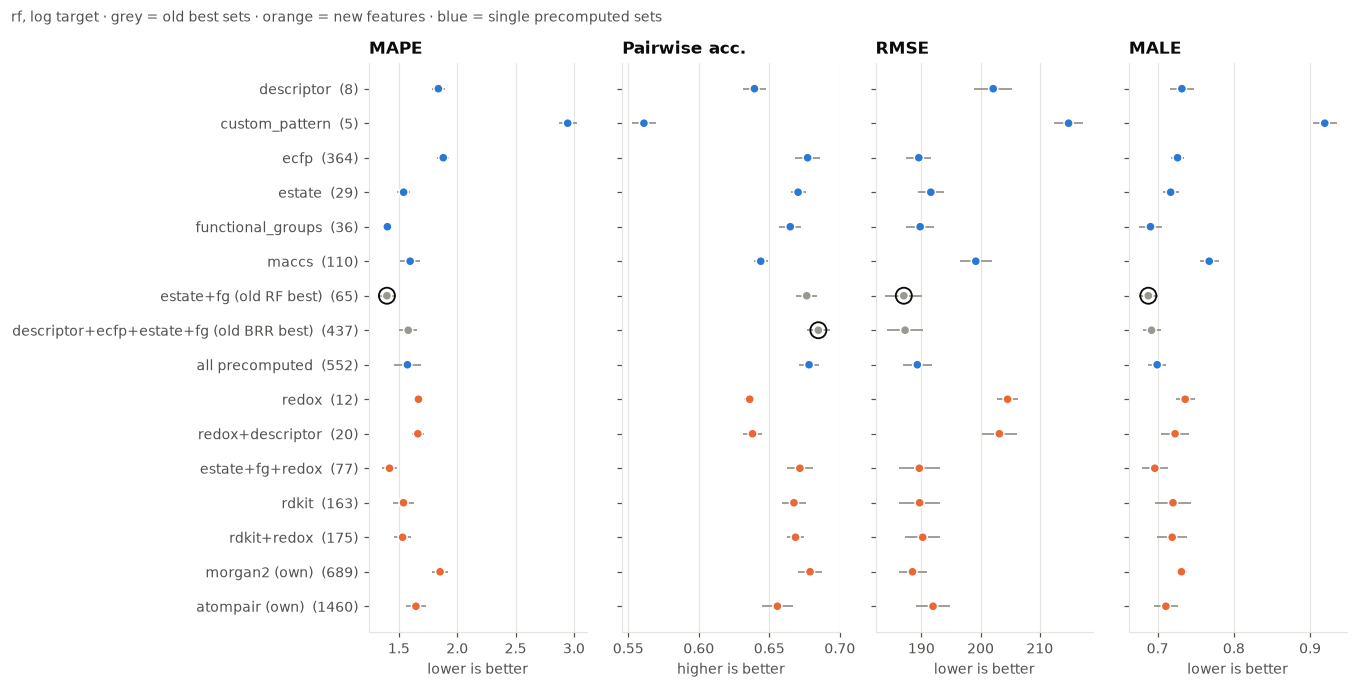

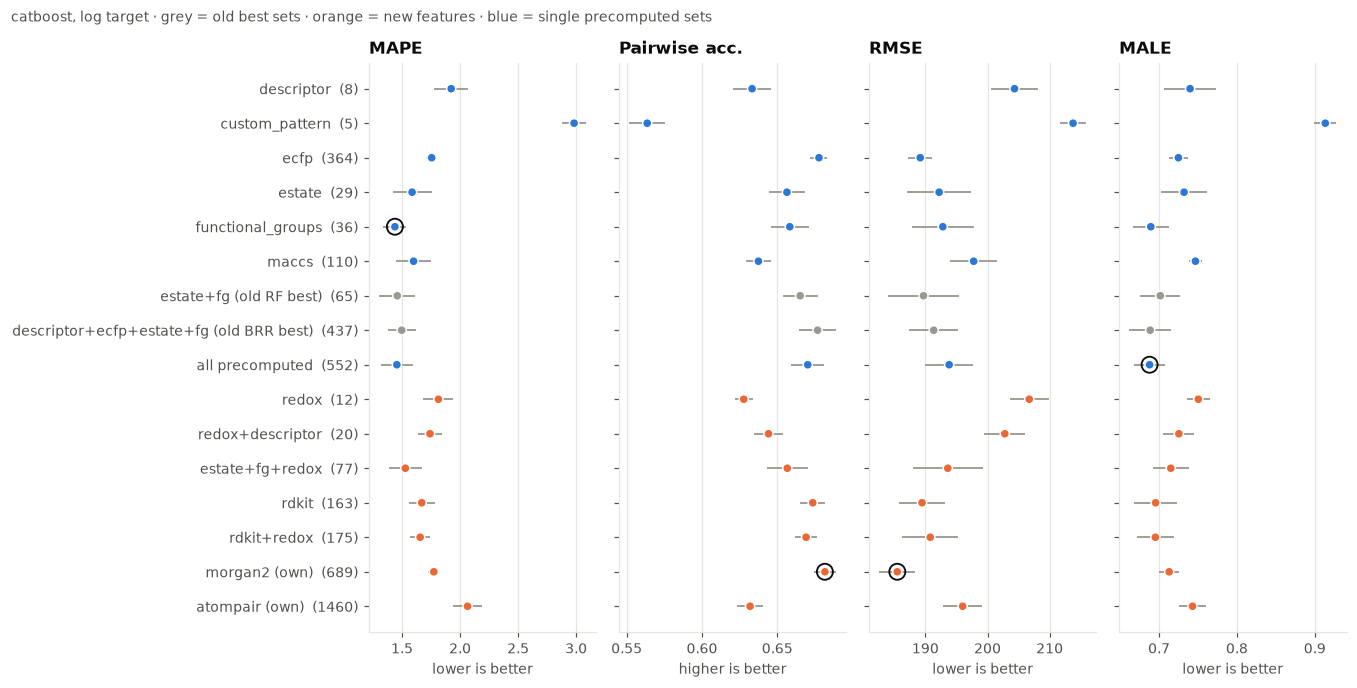

In [5]:
for algo in MODELS:
    sub = summary[summary["algo"] == algo].assign(label=lambda d: d["features"] + "  (" + d["n_features"].astype(str) + ")")
    old = {"estate+fg (old RF best)", "descriptor+ecfp+estate+fg (old BRR best)"}
    new = {"redox", "redox+descriptor", "estate+fg+redox", "rdkit", "rdkit+redox", "morgan2 (own)", "atompair (own)"}
    hl = {lab: plots.GRAY if f in old else plots.ORANGE if f in new else plots.BLUE for lab, f in zip(sub["label"], sub["features"])}
    fig = plots.metric_dots(sub, highlight=hl, label_col="label")
    fig.suptitle(f"{algo}, log target · grey = old best sets · orange = new features · blue = single precomputed sets", x=0.01, ha="left", fontsize=9, color=plots.INK_2)
    fig.tight_layout()

## Which features does the forest use?

Impurity importance of a random forest (log target) fitted on all data with EState + functional
groups + redox features. Only a rough guide: correlated features share importance.
Names: `fr_*` are RDKit fragment counts (the precomputed `functional_groups_i` columns) and
`estate_*` are EState sums per atom type (e.g. `sNH2` = primary amine N, `aaCH` = aromatic CH).

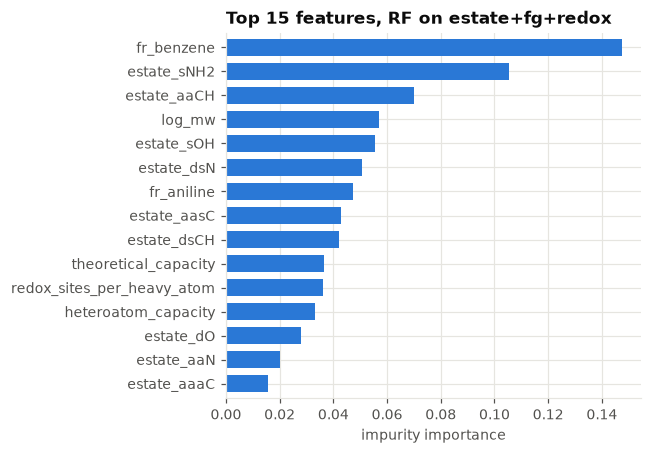

In [6]:
X_imp = FEATURES["estate+fg+redox"]
rf = RandomForestRegressor(500, min_samples_leaf=2, max_features=0.3, random_state=0, n_jobs=-1).fit(X_imp, np.log(y))
imp = pd.Series(rf.feature_importances_, index=readable_names(X_imp.columns)).sort_values().tail(15)
fig, ax = plt.subplots(figsize=(6, 4.2))
imp.plot.barh(ax=ax, color=plots.BLUE, width=0.7)
ax.set(xlabel="impurity importance")
ax.set_title("Top 15 features, RF on estate+fg+redox", loc="left")
fig.tight_layout()

## Takeaways

- Differences between the good feature sets are small (pairwise accuracy 0.665–0.685, std ≈ 0.01).
  No set clearly beats the old best ones, so the old greedy selection did find reasonable sets.
- **Best pairwise accuracy:** fingerprint-containing sets (old BRR best set 0.685 with RF, Morgan
  0.682 with CatBoost, ECFP 0.677). **Best MAPE / MALE:** EState + functional groups (RF 1.40 / 0.688).
- The **redox / theoretical-capacity features don't help**: alone they are weak (PA ≈ 0.63) and adding
  them to EState + functional groups changes nothing measurable, despite the physical motivation.
- The forest relies mostly on simple composition signals, all negatively correlated with capacity:
  number of benzene rings (Spearman ρ = −0.52), aromatic CH (−0.39), molecular weight (−0.40),
  anilines (−0.26), primary amines sNH2 (−0.24) and OH (−0.20). Large, carbon-rich aromatic
  substrates, and the amine-containing pre-joined imines, tend to have lower capacity.
- Defaults from here on: **EState + functional groups** for MAPE, **descriptor + ECFP + EState + fg**
  for ranking.